In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df=pd.read_csv("/content/ecommerce_customer_behavior_dataset.csv")
df.head(4)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,Mobile,8,10,False,1,4


In [ ]:
df['Quantity'].value_counts()

,count
Quantity,
1,2242
2,1073
3,590
5,562
4,533


In [ ]:
df['Device_Type'].value_counts()

,count
Device_Type,
Mobile,2795
Desktop,1711
Tablet,494


In [ ]:
print("shape:\n",df.shape)
print("info:\n",df.info())

shape:
 (5000, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Order_ID                  5000 non-null   object 
 1   Customer_ID               5000 non-null   object 
 2   Date                      5000 non-null   object 
 3   Age                       5000 non-null   int64  
 4   Gender                    5000 non-null   object 
 5   City                      5000 non-null   object 
 6   Product_Category          5000 non-null   object 
 7   Unit_Price                5000 non-null   float64
 8   Quantity                  5000 non-null   int64  
 9   Discount_Amount           5000 non-null   float64
 10  Total_Amount              5000 non-null   float64
 11  Payment_Method            5000 non-null   object 
 12  Device_Type               5000 non-null   object 
 13  Session_Duration_Minutes  5000 non-null   in

## Dataset contains 5000 rows and 18 columns

In [ ]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Date', 'Age', 'Gender', 'City',
       'Product_Category', 'Unit_Price', 'Quantity', 'Discount_Amount',
       'Total_Amount', 'Payment_Method', 'Device_Type',
       'Session_Duration_Minutes', 'Pages_Viewed', 'Is_Returning_Customer',
       'Delivery_Time_Days', 'Customer_Rating'],
      dtype='object')

In [ ]:
print("missing value:\n",df.isnull().sum())

missing value:
 Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64


In [ ]:
print("Nan values count\n:",df.isna().sum())

Nan values count
: Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64


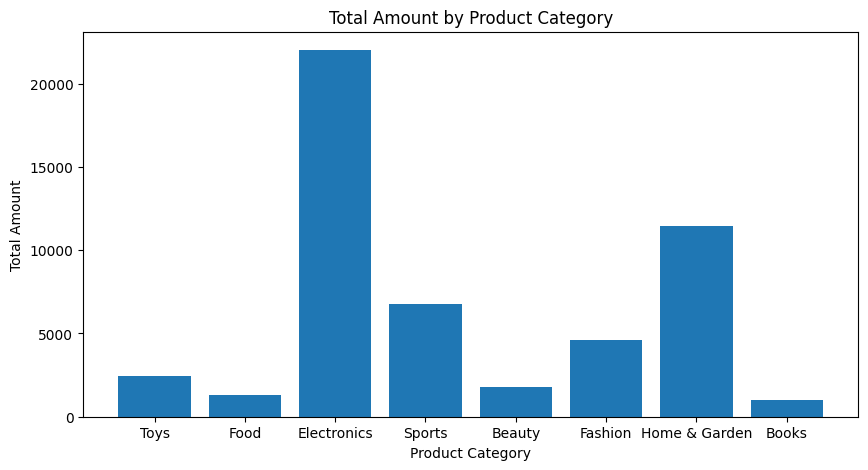

The total sales was done in electronics and home garden


In [3]:
plt.figure(figsize=(10,5))
plt.bar(df['Product_Category'],df['Total_Amount'])
plt.title('Total Amount by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Amount')
plt.show()
print("The total sales was done in electronics and home garden")

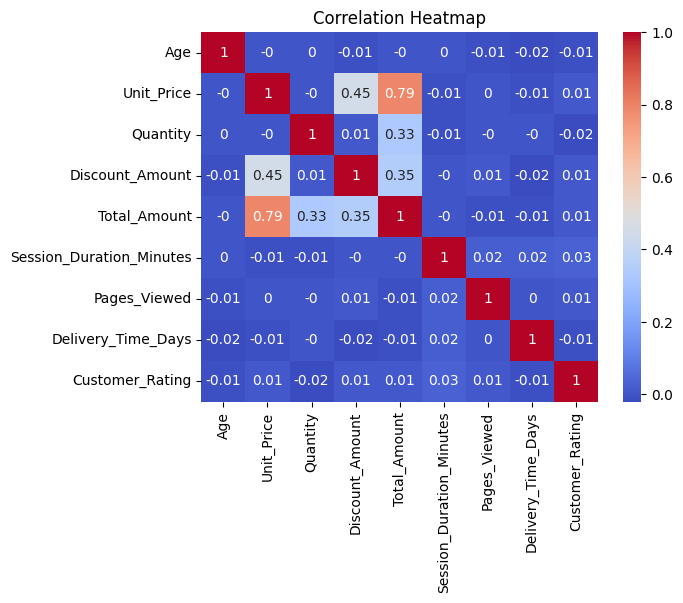

In [20]:
num_df=df.select_dtypes(include=['int64','float64'])
sns.heatmap(num_df.corr().round(2),annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

1. The overall sales broken down by device type, gender, and product
2. Do more pages viewed and longer sessions result in higher sales?
3. Does customer rating correlate with delivery time?

In [4]:
# 1 . The overall sales broken down by device type, gender and product.
pivot = df.pivot_table(
    values="Total_Amount",
    index="Product_Category",
    columns=["Gender", "Device_Type"],
    aggfunc="sum",
    margins=True
)
pivot

Gender               Female                              Male              \
Device_Type         Desktop      Mobile     Tablet    Desktop      Mobile   
Product_Category                                                            
Beauty             22173.41    47547.86    6939.16   29905.78    43415.17   
Books              12951.13    17791.95    3655.04   10867.93    21536.88   
Electronics       306863.88   698878.23  128547.56  421676.42   636463.74   
Fashion            68391.89   105266.29   10761.78   63726.74   109819.86   
Food               13699.94    25004.79    4675.98   14789.25    30384.01   
Home & Garden     156128.06   281090.26   39038.47  156111.14   233949.27   
Sports            141899.10   231399.04   38688.83  115564.64   198149.27   
Toys               41139.22    59735.46   11741.93   42724.62    53576.83   
All               763246.63  1466713.88  244048.75  855366.52  1327295.03   

Gender                          Other                             All  
Device_Type          Tablet   Desktop    Mobile    Tablet              
Product_Category                                                       
Beauty              4579.00    761.50   1156.84    106.02   156584.74  
Books               4050.50    743.75    916.18    231.16    72744.52  
Electronics       104195.20  20911.22   3963.36   7307.20  2328806.81  
Fashion            14359.68   1128.26   1760.43       NaN   375214.93  
Food                4816.62    448.63   1717.28    602.17    96138.67  
Home & Garden      32719.23   6479.21   1660.48   1172.74   908348.86  
Sports             22293.82    480.97   3994.37   2093.52   754563.56  
Toys               11353.10    537.09   1290.79   1043.44   223142.48  
All               198367.15  31490.63  16459.73  12556.25  4915544.57

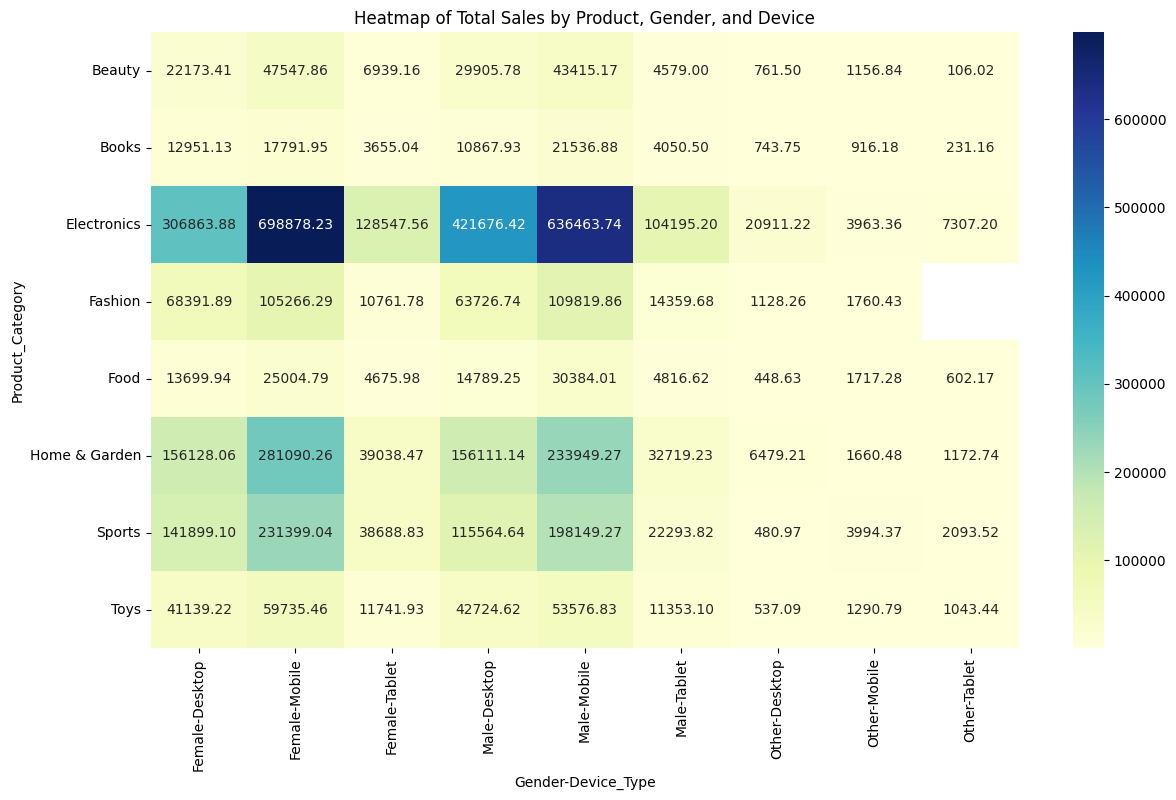

In [ ]:
plt.figure(figsize=(14, 8))
sns.heatmap(pivot_for_graph, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Heatmap of Total Sales by Product, Gender, and Device")
plt.show()

In [8]:
df.tail(2)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
4998,ORD_004443,CUST_04443,2024-03-26,41,Female,Istanbul,Fashion,171.19,1,0.00,171.19,Credit Card,Mobile,20,12,True,5,4
4999,ORD_000902,CUST_00902,2024-03-26,30,Female,Konya,Books,84.30,4,21.72,315.48,Debit Card,Desktop,8,9,True,5,5


In [10]:
#2.Do more pages viewed and longer sessions result in higher sales?
#let's take sales as independent variable then pages_viewed and sessions viewed be dependent variable
#now lets frame linear regression

x=df[['Pages_Viewed','Session_Duration_Minutes','Delivery_Time_Days','Customer_Rating','Unit_Price']]
y=df['Total_Amount']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

model=LinearRegression()
model.fit(x_train,y_train)

y_pred=model.predict(x_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("R-squared:", r2,"\nMean Absolute Error:", mae,"\nRoot Mean Squared Error:", rmse)


R-squared: 0.6342375531518154 
Mean Absolute Error: 462.0170370290748 
Root Mean Squared Error: 892.8963268216628


In [16]:
#3. Does customer rating correlate with delivery time?
corr_matrix = df[['Delivery_Time_Days', 'Customer_Rating']].corr()
print(corr_matrix)

                    Delivery_Time_Days  Customer_Rating
Delivery_Time_Days            1.000000        -0.009948
Customer_Rating              -0.009948         1.000000


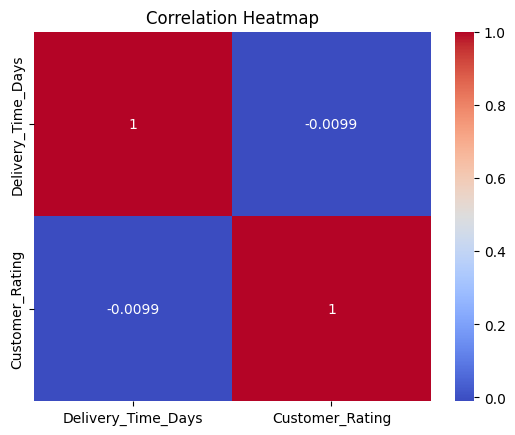

In [15]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
*